# FBCL Model

# Abalation Study

Using device: cuda
Training file: preprocessed_augmented_dataset_scaled.csv
Validation file: validation_set_scaled.csv
Test file: test_set_scaled.csv
Number of features: 19 | Number of classes: 10

Running variant: 0_baseline_exact


/tmp/ipykernel_626/1016130204.py:208: UserWarning: enable_nested_tensor is True, but self.use_nested_tensor is False because encoder_layer.norm_first was True
  self.transformer = nn.TransformerEncoder(encoder_layer, num_layers=cfg["n_layers"])


0_baseline_exact:Severity_007 Ep 1/2:   0%|          | 0/391 [00:00<?, ?it/s]

0_baseline_exact:Severity_007 Ep 2/2:   0%|          | 0/391 [00:00<?, ?it/s]

0_baseline_exact:Severity_014 Ep 1/2:   0%|          | 0/391 [00:00<?, ?it/s]

0_baseline_exact:Severity_014 Ep 2/2:   0%|          | 0/391 [00:00<?, ?it/s]

... (31 outputs left out)

4_fixed_lr_no_schedule:Severity_014 Ep 2/2:   0%|          | 0/391 [00:00<?, ?it/s]

4_fixed_lr_no_schedule:Severity_021 Ep 1/2:   0%|          | 0/391 [00:00<?, ?it/s]

4_fixed_lr_no_schedule:Severity_021 Ep 2/2:   0%|          | 0/391 [00:00<?, ?it/s]

  -> Accuracy: 0.9424 | F1: 0.9422 | Params: 6,236,703

ABLATION STUDY RESULTS (sorted by F1 score, weighted)
 accuracy  precision   recall  f1_score                    variant  params
 0.951515   0.951644 0.951515  0.950953          2_no_distillation 6236703
 0.948485   0.948160 0.948485  0.947823        1_no_boosting_heads 5702667
 0.942424   0.943561 0.942424  0.942724 3_single_transformer_layer 2287903
 0.942424   0.943221 0.942424  0.942167           0_baseline_exact 6236703
 0.942424   0.943221 0.942424  0.942167     4_fixed_lr_no_schedule 6236703

Saved: fbcl_ablation_results.csv


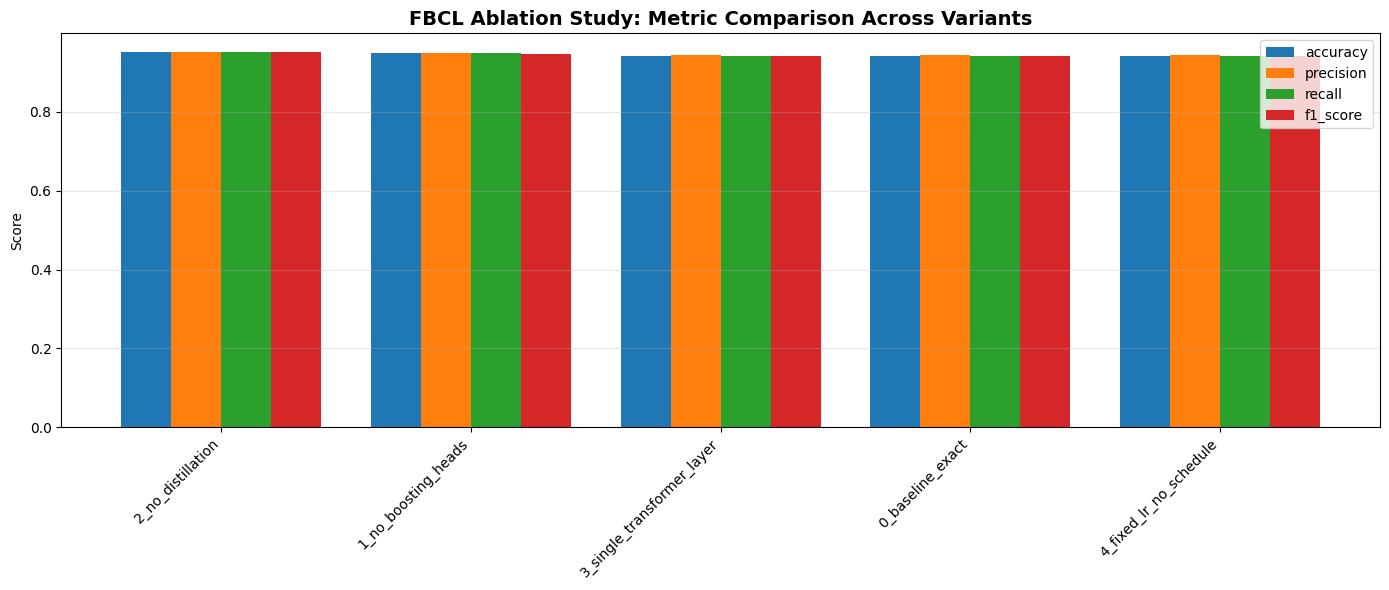

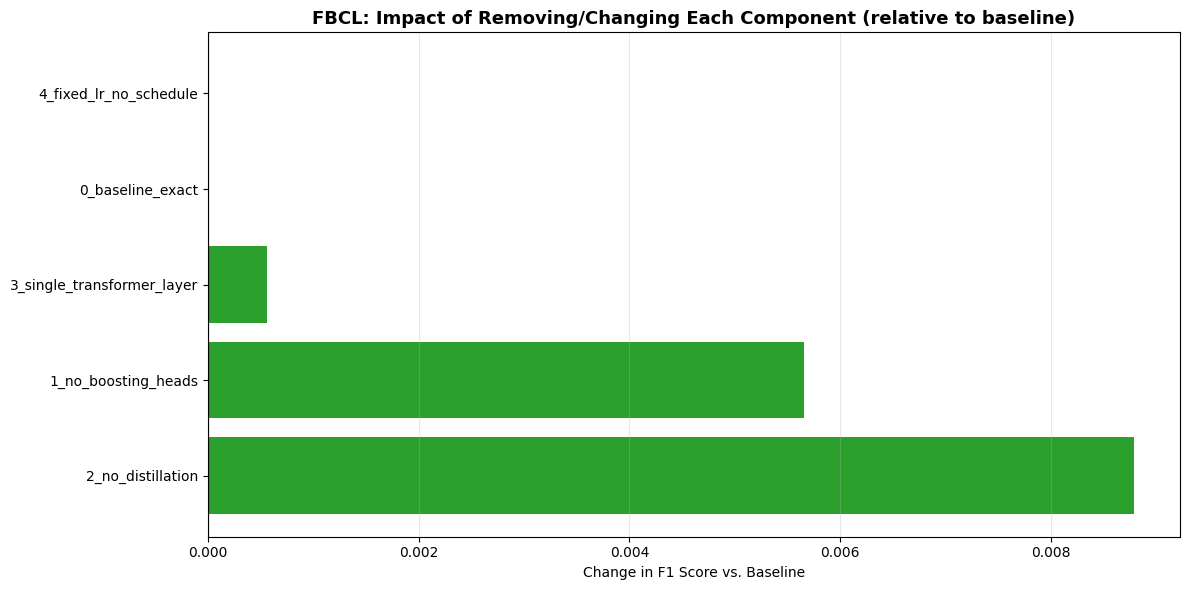


Saved plots: fbcl_ablation_metric_comparison.png, fbcl_ablation_delta_from_baseline.png

SUMMARY: Component impact (F1 delta vs baseline)
                   variant  f1_delta_vs_baseline  params
    4_fixed_lr_no_schedule              0.000000 6236703
3_single_transformer_layer              0.000557 2287903
       1_no_boosting_heads              0.005656 5702667
         2_no_distillation              0.008786 6236703


In [ ]:
# ============================================================
# ABLATION STUDY: FBCL (FEATURE BOOSTING CONTINUAL LEARNING) FOR BEARING FAULT DETECTION
# Variants tested:
#   0. Full FBCL model (baseline)
#   1. No boosting heads
#   2. No knowledge distillation
#   3. Single Transformer layer instead of 6-layer encoder
#   4. Fixed learning rate, no cosine learning rate scheduler
# ============================================================

# !pip -q install torch torchvision torchaudio pandas numpy scikit-learn tqdm matplotlib

import copy
import json
import random
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import os

import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import TensorDataset, DataLoader, WeightedRandomSampler

from sklearn.preprocessing import LabelEncoder, StandardScaler
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score
from sklearn.utils.class_weight import compute_class_weight

from tqdm.auto import tqdm

# from google.colab import files
# uploaded = files.upload()


def set_seed(seed=42):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)
    torch.backends.cudnn.deterministic = True
    torch.backends.cudnn.benchmark = False
    os.environ['PYTHONHASHSEED'] = str(seed)


SEED = 42
set_seed(SEED)

TARGET_COL = "fault_encoded"
TASK_NAMES = ['Severity_007', 'Severity_014', 'Severity_021']

BATCH_SIZE = 256
EPOCHS_PER_TASK = 2   # reduced from 120 for ablation sweep speed
PATIENCE = 8           # reduced from 25

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Using device:", DEVICE)


# ============================================================
# LOAD DATA
# ============================================================

files_list = os.listdir()

def choose_file(kind, uploaded_names):
    lower_names = [name.lower() for name in uploaded_names]
    if kind == "train":
        keywords = ["augmented", "train", "training", "preprocessed"]
    elif kind == "val":
        keywords = ["validation", "val"]
    elif kind == "test":
        keywords = ["test"]
    else:
        keywords = []
    candidates = [orig for orig, low in zip(uploaded_names, lower_names) if any(k in low for k in keywords)]
    if len(candidates) == 1:
        return candidates[0]
    raise FileNotFoundError(
        f"Could not automatically choose the {kind} file among: {uploaded_names}. "
        f"Rename your files to clearly contain 'train'/'validation'/'test'."
    )

train_file = choose_file("train", files_list)
val_file = choose_file("val", files_list)
test_file = choose_file("test", files_list)

print("Training file:", train_file)
print("Validation file:", val_file)
print("Test file:", test_file)

train_df = pd.read_csv(train_file)
val_df = pd.read_csv(val_file)
test_df = pd.read_csv(test_file)

if TARGET_COL not in train_df.columns:
    raise ValueError(f"Target column '{TARGET_COL}' not found. Columns: {list(train_df.columns)}")

feature_cols = [c for c in train_df.columns if c != TARGET_COL]

for df in [train_df, val_df, test_df]:
    for col in feature_cols:
        df[col] = pd.to_numeric(df[col], errors="coerce")
    df[feature_cols] = df[feature_cols].fillna(0)

label_encoder = LabelEncoder()
all_labels = pd.concat([train_df[TARGET_COL], val_df[TARGET_COL], test_df[TARGET_COL]], axis=0)
label_encoder.fit(all_labels)

X_train = train_df[feature_cols].values.astype(np.float32)
y_train = label_encoder.transform(train_df[TARGET_COL])
X_val = val_df[feature_cols].values.astype(np.float32)
y_val = label_encoder.transform(val_df[TARGET_COL])
X_test = test_df[feature_cols].values.astype(np.float32)
y_test = label_encoder.transform(test_df[TARGET_COL])

n_features = X_train.shape[1]
n_classes = len(label_encoder.classes_)
print("Number of features:", n_features, "| Number of classes:", n_classes)

scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_val_scaled = scaler.transform(X_val)
X_test_scaled = scaler.transform(X_test)

X_train_t = torch.tensor(X_train_scaled, dtype=torch.float32)
X_val_t = torch.tensor(X_val_scaled, dtype=torch.float32)
X_test_t = torch.tensor(X_test_scaled, dtype=torch.float32)
y_train_t = torch.tensor(y_train, dtype=torch.long)
y_val_t = torch.tensor(y_val, dtype=torch.long)
y_test_t = torch.tensor(y_test, dtype=torch.long)

class_weights_np = compute_class_weight('balanced', classes=np.unique(y_train), y=y_train)
sample_weights = class_weights_np[y_train]
sample_weights_t = torch.tensor(sample_weights, dtype=torch.float32)

train_dataset = TensorDataset(X_train_t, y_train_t)
val_dataset = TensorDataset(X_val_t, y_val_t)
test_dataset = TensorDataset(X_test_t, y_test_t)

val_loader = DataLoader(val_dataset, batch_size=BATCH_SIZE, shuffle=False, num_workers=0)
test_loader = DataLoader(test_dataset, batch_size=BATCH_SIZE, shuffle=False, num_workers=0)


def make_train_loader(cfg):
    if cfg["use_weighted_sampler"]:
        sampler = WeightedRandomSampler(sample_weights_t, len(sample_weights_t), replacement=True)
        return DataLoader(train_dataset, batch_size=BATCH_SIZE, sampler=sampler, num_workers=0)
    else:
        return DataLoader(train_dataset, batch_size=BATCH_SIZE, shuffle=True, num_workers=0)


# ============================================================
# CONFIGURABLE FBCL MODEL
# ============================================================

DEFAULT_CONFIG = {
    "name": "0_baseline_exact",
    "d_model": 256,
    "n_heads": 16,
    "n_layers": 6,
    "dropout": 0.15,
    "boosting_dropout": 0.12,
    "use_boosting_heads": True,
    "use_distillation": True,
    "use_batchnorm": True,
    "use_dropout": True,
    "use_weighted_sampler": True,
    "use_grad_clip": True,
    "use_lr_schedule": True,
    "lr": 3e-4,
    "weight_decay": 5e-5,
    "temperature": 2.5,
    "distillation_alpha": 0.8,
}


def norm_layer(cfg, dim):
    return nn.BatchNorm1d(dim) if cfg["use_batchnorm"] else nn.Identity()


def dropout_layer(cfg, p):
    return nn.Dropout(p if cfg["use_dropout"] else 0.0)


class ConfigurableFBCLTransformer(nn.Module):
    def __init__(self, cfg, n_features, n_classes):
        super().__init__()
        self.cfg = cfg
        self.n_features = n_features
        self.d_model = cfg["d_model"]
        self.n_classes = n_classes

        d_model = cfg["d_model"]

        self.feature_embedding = nn.Sequential(
            nn.Linear(1, d_model // 2),
            nn.GELU(),
            nn.Linear(d_model // 2, d_model)
        )

        self.pos_embedding = nn.Parameter(torch.randn(1, n_features, d_model) * 0.02)
        self.pos_scale = nn.Parameter(torch.ones(1))

        encoder_layer = nn.TransformerEncoderLayer(
            d_model=d_model,
            nhead=cfg["n_heads"],
            dim_feedforward=d_model * 4,
            dropout=cfg["dropout"] if cfg["use_dropout"] else 0.0,
            batch_first=True,
            activation='gelu',
            norm_first=True
        )
        self.transformer = nn.TransformerEncoder(encoder_layer, num_layers=cfg["n_layers"])
        self.layer_norm = nn.LayerNorm(d_model)
        self.dropout = dropout_layer(cfg, cfg["dropout"])

        self.classifier = nn.Sequential(
            nn.Linear(d_model, d_model * 4),
            norm_layer(cfg, d_model * 4),
            nn.GELU(),
            dropout_layer(cfg, cfg["dropout"]),
            nn.Linear(d_model * 4, d_model * 2),
            norm_layer(cfg, d_model * 2),
            nn.GELU(),
            dropout_layer(cfg, cfg["dropout"]),
            nn.Linear(d_model * 2, d_model),
            norm_layer(cfg, d_model),
            nn.GELU(),
            dropout_layer(cfg, cfg["dropout"]),
            nn.Linear(d_model, n_classes)
        )

        self.boosting_heads = nn.ModuleList()

    def add_boosting_head(self):
        cfg = self.cfg
        d_model = self.d_model
        head = nn.Sequential(
            nn.Linear(d_model, d_model * 2),
            norm_layer(cfg, d_model * 2),
            nn.GELU(),
            dropout_layer(cfg, cfg["boosting_dropout"]),
            nn.Linear(d_model * 2, d_model),
            norm_layer(cfg, d_model),
            nn.GELU(),
            dropout_layer(cfg, cfg["boosting_dropout"]),
            nn.Linear(d_model, self.n_classes)
        )
        self.boosting_heads.append(head)
        return head

    def forward(self, x, use_boosting=False):
        batch_size, n_feat = x.shape
        x = x.unsqueeze(-1)
        x = self.feature_embedding(x)
        x = x + self.pos_scale * self.pos_embedding[:, :n_feat, :]
        x = self.dropout(x)
        x = self.transformer(x)
        x = self.layer_norm(x)
        x = x.mean(dim=1)

        logits = self.classifier(x)

        if use_boosting and len(self.boosting_heads) > 0:
            for head in self.boosting_heads:
                logits = logits + head(x)

        return logits


def distillation_loss(student_logits, teacher_logits, labels, temperature, alpha):
    soft_targets = F.softmax(teacher_logits / temperature, dim=1)
    soft_loss = F.kl_div(
        F.log_softmax(student_logits / temperature, dim=1),
        soft_targets,
        reduction='batchmean'
    ) * (temperature ** 2)
    hard_loss = F.cross_entropy(student_logits, labels)
    return alpha * soft_loss + (1 - alpha) * hard_loss


def train_task(cfg, model, train_loader, val_loader, teacher_model=None, epochs=25, task_name="Task"):
    use_distill = cfg["use_distillation"] and teacher_model is not None
    if use_distill:
        teacher_model.to(DEVICE)
        teacher_model.eval()

    optimizer = torch.optim.AdamW(model.parameters(), lr=cfg["lr"], weight_decay=cfg["weight_decay"])
    scheduler = None
    if cfg["use_lr_schedule"]:
        scheduler = torch.optim.lr_scheduler.CosineAnnealingWarmRestarts(optimizer, T_0=20, T_mult=2)

    best_val_acc = 0.0
    best_state = None
    patience_counter = 0

    for epoch in range(1, epochs + 1):
        model.train()
        for xb, yb in tqdm(train_loader, desc=f"{task_name} Ep {epoch}/{epochs}", leave=False):
            xb, yb = xb.to(DEVICE), yb.to(DEVICE)

            optimizer.zero_grad()
            logits = model(xb, use_boosting=cfg["use_boosting_heads"])

            if use_distill:
                with torch.no_grad():
                    teacher_logits = teacher_model(xb, use_boosting=cfg["use_boosting_heads"])
                loss = distillation_loss(logits, teacher_logits, yb, cfg["temperature"], cfg["distillation_alpha"])
            else:
                loss = F.cross_entropy(logits, yb)

            loss.backward()
            if cfg["use_grad_clip"]:
                torch.nn.utils.clip_grad_norm_(model.parameters(), max_norm=1.0)
            optimizer.step()

        model.eval()
        val_preds, val_labels = [], []
        with torch.no_grad():
            for xb, yb in val_loader:
                xb, yb = xb.to(DEVICE), yb.to(DEVICE)
                logits = model(xb, use_boosting=cfg["use_boosting_heads"])
                val_preds.extend(logits.argmax(dim=1).cpu().numpy())
                val_labels.extend(yb.cpu().numpy())

        val_acc = accuracy_score(val_labels, val_preds)

        if scheduler is not None:
            scheduler.step()

        if val_acc > best_val_acc:
            best_val_acc = val_acc
            best_state = copy.deepcopy(model.state_dict())
            patience_counter = 0
        else:
            patience_counter += 1
            if patience_counter >= PATIENCE:
                break

    model.load_state_dict(best_state)
    return model, best_val_acc


def evaluate_model(cfg, model, loader):
    model.eval()
    all_preds, all_labels = [], []
    with torch.no_grad():
        for xb, yb in loader:
            xb, yb = xb.to(DEVICE), yb.to(DEVICE)
            logits = model(xb, use_boosting=cfg["use_boosting_heads"])
            all_preds.extend(logits.argmax(dim=1).cpu().numpy())
            all_labels.extend(yb.cpu().numpy())

    return {
        "accuracy": accuracy_score(all_labels, all_preds),
        "precision": precision_score(all_labels, all_preds, average='weighted', zero_division=0),
        "recall": recall_score(all_labels, all_preds, average='weighted', zero_division=0),
        "f1_score": f1_score(all_labels, all_preds, average='weighted', zero_division=0),
    }


def run_continual_experiment(cfg):
    """Runs the full 3-task continual learning sequence for one config."""
    set_seed(SEED)
    model = ConfigurableFBCLTransformer(cfg, n_features, n_classes).to(DEVICE)

    all_models = []
    for task_idx, task_name in enumerate(TASK_NAMES):
        if task_idx > 0 and cfg["use_boosting_heads"]:
            new_head = model.add_boosting_head()
            new_head.to(DEVICE)

        teacher = all_models[-1] if all_models else None
        train_loader = make_train_loader(cfg)

        model, val_acc = train_task(
            cfg, model, train_loader, val_loader,
            teacher_model=teacher,
            epochs=EPOCHS_PER_TASK,
            task_name=f"{cfg['name']}:{task_name}"
        )
        all_models.append(copy.deepcopy(model))

    metrics = evaluate_model(cfg, model, test_loader)
    metrics["variant"] = cfg["name"]
    metrics["params"] = sum(p.numel() for p in model.parameters())
    return metrics


# ============================================================
# DEFINE ABLATION VARIANTS
# ============================================================

def make_cfg(overrides):
    cfg = dict(DEFAULT_CONFIG)
    cfg.update(overrides)
    return cfg


ablation_variants = [
    make_cfg({"name": "0_baseline_exact"}),
    make_cfg({"name": "1_no_boosting_heads", "use_boosting_heads": False}),
    make_cfg({"name": "2_no_distillation", "use_distillation": False}),
    make_cfg({"name": "3_single_transformer_layer", "n_layers": 1}),
    make_cfg({"name": "4_fixed_lr_no_schedule", "use_lr_schedule": False}),
]


# ============================================================
# RUN ALL EXPERIMENTS
# ============================================================

results = []
for cfg in ablation_variants:
    print("\n" + "=" * 70)
    print(f"Running variant: {cfg['name']}")
    print("=" * 70)
    metrics = run_continual_experiment(cfg)
    results.append(metrics)
    print(f"  -> Accuracy: {metrics['accuracy']:.4f} | F1: {metrics['f1_score']:.4f} "
          f"| Params: {metrics['params']:,}")

results_df = pd.DataFrame(results).sort_values("f1_score", ascending=False).reset_index(drop=True)

print("\n" + "=" * 70)
print("ABLATION STUDY RESULTS (sorted by F1 score, weighted)")
print("=" * 70)
print(results_df.to_string(index=False))

results_df.to_csv("fbcl_ablation_results.csv", index=False)
print("\nSaved: fbcl_ablation_results.csv")


# ============================================================
# VISUALIZATIONS
# ============================================================

baseline_row = results_df[results_df["variant"] == "0_baseline_exact"].iloc[0]

plt.figure(figsize=(14, 6))
metrics_to_plot = ["accuracy", "precision", "recall", "f1_score"]
x = np.arange(len(results_df))
width = 0.2
for i, metric in enumerate(metrics_to_plot):
    plt.bar(x + i * width, results_df[metric], width, label=metric)
plt.xticks(x + width * 1.5, results_df["variant"], rotation=45, ha='right')
plt.ylabel("Score")
plt.title("FBCL Ablation Study: Metric Comparison Across Variants", fontsize=14, fontweight='bold')
plt.legend()
plt.grid(True, axis='y', alpha=0.3)
plt.tight_layout()
plt.savefig("fbcl_ablation_metric_comparison.png", dpi=150)
plt.show()

plt.figure(figsize=(12, 6))
delta_f1 = results_df["f1_score"] - baseline_row["f1_score"]
colors = ['#d62728' if v < 0 else '#2ca02c' for v in delta_f1]
plt.barh(results_df["variant"], delta_f1, color=colors)
plt.axvline(0, color='black', linewidth=0.8)
plt.xlabel("Change in F1 Score vs. Baseline")
plt.title("FBCL: Impact of Removing/Changing Each Component (relative to baseline)",
          fontsize=13, fontweight='bold')
plt.grid(True, axis='x', alpha=0.3)
plt.tight_layout()
plt.savefig("fbcl_ablation_delta_from_baseline.png", dpi=150)
plt.show()

print("\nSaved plots: fbcl_ablation_metric_comparison.png, fbcl_ablation_delta_from_baseline.png")

# ============================================================
# SUMMARY
# ============================================================
print("\n" + "=" * 70)
print("SUMMARY: Component impact (F1 delta vs baseline)")
print("=" * 70)
summary = results_df.copy()
summary["f1_delta_vs_baseline"] = summary["f1_score"] - baseline_row["f1_score"]
summary = summary[summary["variant"] != "0_baseline_exact"]
summary = summary.sort_values("f1_delta_vs_baseline")
print(summary[["variant", "f1_delta_vs_baseline", "params"]].to_string(index=False))